In [7]:
import torch
import torchvision
import numpy as np
import matplotlib.pyplot as plt


In [8]:
from src.helper_evaluation import set_all_seeds, set_deterministic, compute_confusion_matrix
from src.helper_train import train_model
from src.helper_plotting import plot_training_loss, plot_accuracy, show_examples, plot_confusion_matrix
from src.helper_dataset import get_dataloaders_mnist
from src.model import LeNet5

In [9]:
# Settings
RANDOM_SEED=123
BATCH_SIZE=256
NUM_EPOCHS=15
DEVICE = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

In [10]:
set_all_seeds(RANDOM_SEED)

In [11]:
# MNIST DATASET
resize_transform = torchvision.transforms.Compose(
    [torchvision.transforms.Resize((32, 32)),
     torchvision.transforms.ToTensor(),
     torchvision.transforms.Normalize((0.5,), (0.5,))])


train_loader, valid_loader, test_loader = get_dataloaders_mnist(
    batch_size=BATCH_SIZE,
    validation_fraction=0.1,
    train_transforms=resize_transform,
    test_transforms=resize_transform)

# Checking the dataset
for images, labels in train_loader:
    print('Image batch dimensions:', images.shape)
    print('Image label dimensions:', labels.shape)
    print('Class labels of 10 examples:', labels[:10])
    break

100%|██████████| 9.91M/9.91M [00:00<00:00, 18.2MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 526kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.48MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 15.3MB/s]


Image batch dimensions: torch.Size([256, 1, 32, 32])
Image label dimensions: torch.Size([256])
Class labels of 10 examples: tensor([4, 5, 8, 9, 9, 4, 9, 9, 3, 9])


Epoch: 001/015 | Batch 0000/0210 | Loss: 2.3033
Epoch: 001/015 | Batch 0100/0210 | Loss: 0.5886
Epoch: 001/015 | Batch 0200/0210 | Loss: 0.2822
Epoch: 001/015 | Train: 91.52% | Validation: 93.60%
Time elapsed: 0.51 min
Epoch: 002/015 | Batch 0000/0210 | Loss: 0.3071
Epoch: 002/015 | Batch 0100/0210 | Loss: 0.2457
Epoch: 002/015 | Batch 0200/0210 | Loss: 0.1650
Epoch: 002/015 | Train: 95.25% | Validation: 96.35%
Time elapsed: 0.99 min
Epoch: 003/015 | Batch 0000/0210 | Loss: 0.1599
Epoch: 003/015 | Batch 0100/0210 | Loss: 0.1967
Epoch: 003/015 | Batch 0200/0210 | Loss: 0.0895
Epoch: 003/015 | Train: 96.79% | Validation: 97.53%
Time elapsed: 1.48 min
Epoch: 004/015 | Batch 0000/0210 | Loss: 0.1095
Epoch: 004/015 | Batch 0100/0210 | Loss: 0.1041
Epoch: 004/015 | Batch 0200/0210 | Loss: 0.0571
Epoch: 004/015 | Train: 97.56% | Validation: 98.07%
Time elapsed: 2.03 min
Epoch: 005/015 | Batch 0000/0210 | Loss: 0.1304
Epoch: 005/015 | Batch 0100/0210 | Loss: 0.0968
Epoch: 005/015 | Batch 0200/

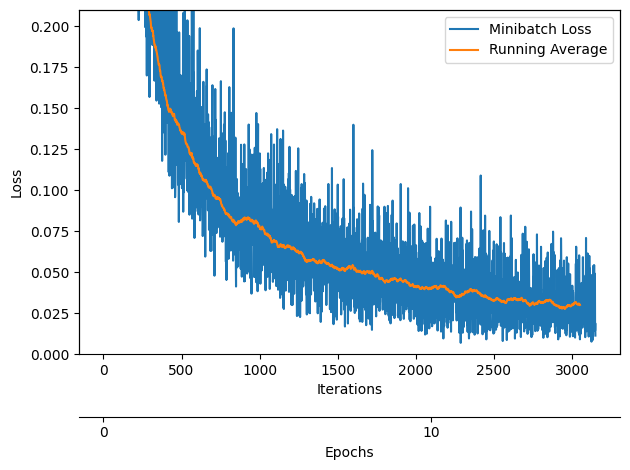

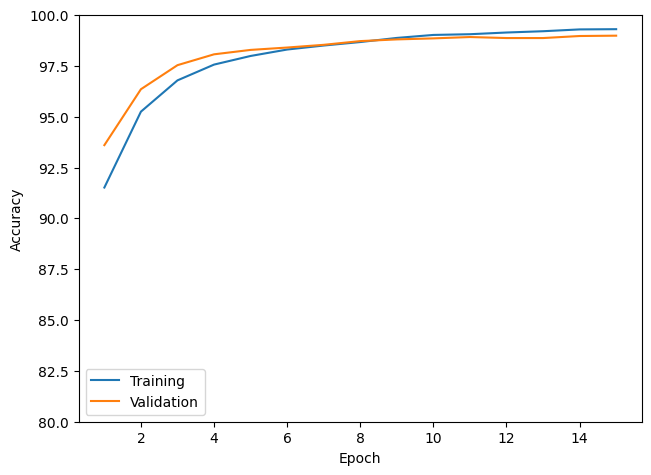

In [12]:
model=LeNet5(grayscale=True, num_classes=10)
model=model.to(DEVICE)

optimizer = torch.optim.SGD(model.parameters(), lr=0.1)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,
                                                       factor=0.1,
                                                       mode='max')

minibatch_loss_list, train_acc_list, valid_acc_list = train_model(
    model=model,
    num_epochs=NUM_EPOCHS,
    train_loader=train_loader,
    valid_loader=valid_loader,
    test_loader=test_loader,
    optimizer=optimizer,
    device=DEVICE,
    logging_interval=100)

plot_training_loss(minibatch_loss_list=minibatch_loss_list,
                   num_epochs=NUM_EPOCHS,
                   iter_per_epoch=len(train_loader),
                   results_dir=None,
                   averaging_iterations=100)
plt.show()

plot_accuracy(train_acc_list=train_acc_list,
              valid_acc_list=valid_acc_list,
              results_dir=None)
plt.ylim([80, 100])
plt.show()

In [13]:
import os

save_dir = "/content/drive/MyDrive/LeNet-5/saved_models"
os.makedirs(save_dir, exist_ok=True)

model_path = os.path.join(save_dir, "lenet5_model.pth")

torch.save({
    'model_state_dict': model.state_dict(),
    'num_classes': 10
}, model_path)

print(f"Model saved at {model_path}")

Model saved at /content/drive/MyDrive/LeNet-5/saved_models/lenet5_model.pth


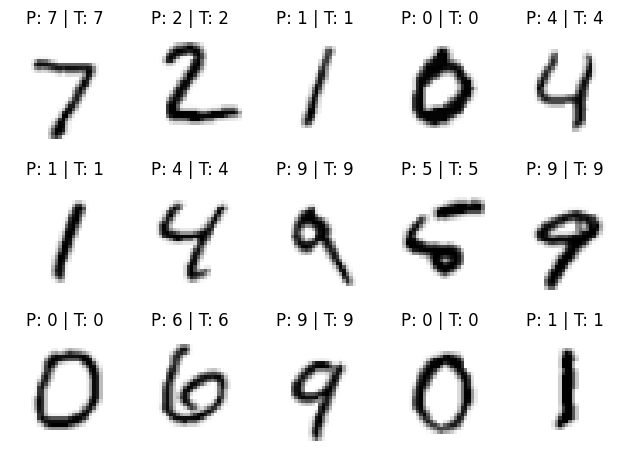

In [14]:
model.cpu()
show_examples(model=model, data_loader=test_loader)


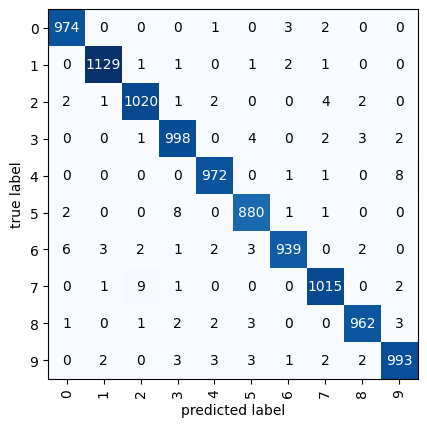

In [15]:
class_dict = {0: '0',
              1: '1',
              2: '2',
              3: '3',
              4: '4',
              5: '5',
              6: '6',
              7: '7',
              8: '8',
              9: '9'}

mat = compute_confusion_matrix(model=model, data_loader=test_loader, device=torch.device('cpu'))
plot_confusion_matrix(mat, class_names=class_dict.values())
plt.show()